# 19 · Final Results on the Official Test File

**The question:** How well does the final detector really work on data it has **never** influenced?

| | |
|---|---|
| **Input** | The frozen final detector (preprocessing 03-05, model 15, calibration 17) and the official testing CSV (82,332 flows) |
| **What we do** | Evaluate **once** on the test file; compare with every earlier model; split results into "seen in training" and "new" flows; check calibration and coverage |
| **Output** | The paper's final tables and figures, and the answers to all five research questions |

**This is the only notebook that predicts the official test file.** Nothing here is tuned: every model, threshold and setting was frozen earlier.
If the score is lower than on `model_selection`, we report that difference as the honest cost of having compared many candidates there.

## 1. Setup and the frozen detector

In [1]:
import sys
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

from src.notebook_helpers import (TRAIN_CSV, TEST_CSV, RAW_SHA256, CLASSES, TARGETS, DATA, MODELS, TABLES, sha256, save_table, save_figure,
                                  save_json, read_json, setup_style)
from src.final_detector import FinalDetector, Preprocessor, network_tensors, prediction_sets, apply_temperature, load_raw
from src import flow_networks as fn
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train'] and sha256(TEST_CSV) == RAW_SHA256['test']

detector = FinalDetector.load()
calibration = read_json(MODELS / '17_calibration.json')
print('Final detector:', detector.name, '| temperature', round(calibration['temperature'], 3), '| conformal alpha', calibration['alpha'])

Final detector: LightGBM (sqrt) | temperature 1.001 | conformal alpha 0.1


## 2. Load the test file and apply the frozen preprocessing

In [2]:
test = load_raw('test')
y_test = pd.Categorical(test.attack_cat, categories=CLASSES).codes.astype(int)
inputs = detector.pre.transform(test)
print(f'test rows: {len(test):,} | tree input {inputs["tree"].shape} | scaled input {inputs["scaled"].shape}')
display(pd.Series(np.bincount(y_test, minlength=10), index=CLASSES, name='test rows').to_frame().T)

test rows: 82,332 | tree input (82332, 195) | scaled input (82332, 195)


,Analysis,Backdoor,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
test rows,677,583,4089,11132,6062,18871,37000,3496,378,44


## 3. The final detector on the test file

In [3]:
def score(y_true, proba):
    return fn.score(y_true, proba)


p_test = apply_temperature(detector.raw_proba(inputs), detector.temperature)
final_scores = score(y_test, p_test)
final_scores['Worms correct (of 44)'] = final_scores.pop('Worms correct (of 13)')   # the test file has 44 Worms rows
display(pd.Series(final_scores).to_frame('final detector on the test file').T)

p, r, f, s = precision_recall_fscore_support(y_test, p_test.argmax(1), labels=range(10), zero_division=0)
per_class = pd.DataFrame({'precision': p, 'recall': r, 'F1': f, 'test rows': s}, index=CLASSES)
save_table(per_class, '19_final_per_class', index=True)
display(per_class.round(3))

,macro F1,accuracy,attack recall,false-positive rate,attack avg precision,Worms correct (of 44)
final detector on the test file,0.5177,0.7276,0.9878,0.3249,0.9868,30.0000


,precision,recall,F1,test rows
Analysis,0.0360,0.1110,0.0540,677
Backdoor,0.0470,0.1900,0.0760,583
DoS,0.3470,0.4250,0.3820,4089
Exploits,0.7250,0.6840,0.7040,11132
Fuzzers,0.2730,0.6270,0.3800,6062
Generic,0.9980,0.9710,0.9840,18871
Normal,0.9780,0.6750,0.7990,37000
Reconnaissance,0.8960,0.8280,0.8610,3496
Shellcode,0.2770,0.9100,0.4250,378
Worms,0.4110,0.6820,0.5130,44


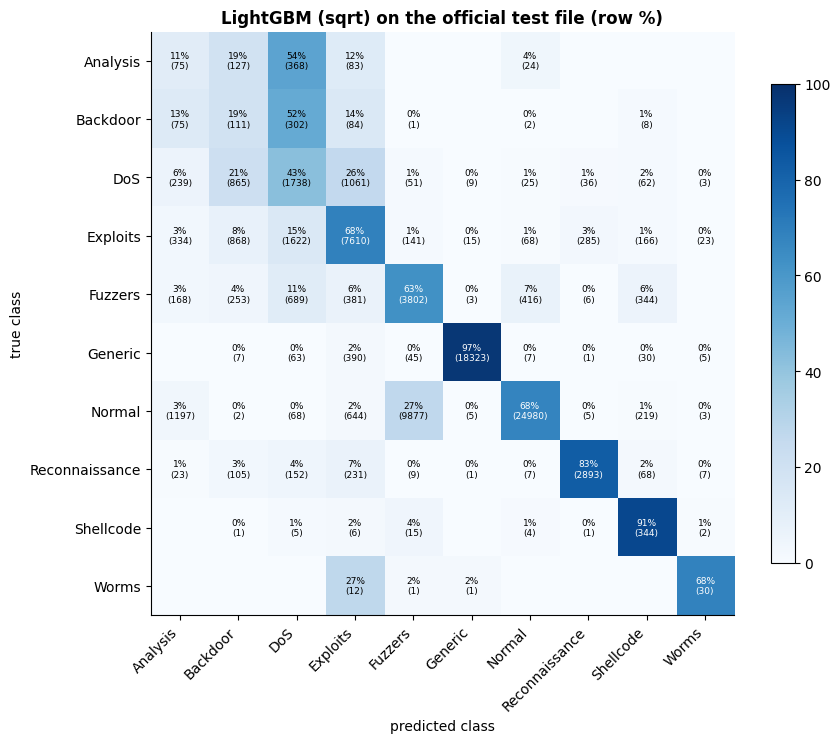

In [4]:
cm = confusion_matrix(y_test, p_test.argmax(1), labels=range(10))
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(10), CLASSES); ax.grid(False)
for i in range(10):
    for j in range(10):
        if cm[i, j]:
            ax.text(j, i, f'{cm_pct[i, j]:.0f}%\n({cm[i, j]})', ha='center', va='center', fontsize=6.5, color='white' if cm_pct[i, j] > 60 else 'black')
ax.set(xlabel='predicted class', ylabel='true class', title=f'{detector.name} on the official test file (row %)')
fig.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); save_figure(fig, '19_final_confusion'); plt.show()

**What we see:**

- On the official test file the final detector reaches **macro F1 0.518** and accuracy 0.728, clearly lower than on `model_selection` (0.666 / 0.818).
- **Attacks are still caught very well:** attack recall 98.8%. Generic (F1 0.98), Reconnaissance (0.86) and Exploits (0.70) remain strong, and
  30 of the 44 Worms flows are found.
- **The big problem is false alarms:** only 67.5% of Normal flows are recognised as Normal (false-positive rate 32.5%). Many Normal flows are labelled
  **Fuzzers**, which makes Fuzzers' precision collapse to 0.27.
- Analysis and Backdoor stay very hard (F1 0.05-0.08), as on every earlier evaluation.

### Why do so many Normal flows raise an alarm?

The false-positive rate is much higher here than on `model_selection`. We check where the Normal test flows go, and compare the most important column
(`sttl`, Notebook 16) between Normal flows in the training and the test file.

In [5]:
normal = CLASSES.index('Normal')
normal_row = pd.Series(cm[normal], index=CLASSES).sort_values(ascending=False)
display(normal_row.head(5).rename('Normal test flows predicted as').to_frame().T)
train_normal = load_raw('train').query("attack_cat == 'Normal'")
ttl = pd.DataFrame({'Normal flows, training file': train_normal.sttl.value_counts(normalize=True),
                    'Normal flows, test file': test[test.attack_cat == 'Normal'].sttl.value_counts(normalize=True)}).fillna(0)
ttl = ttl[ttl.max(axis=1) > 0.01].sort_index()
save_table(ttl, '19_normal_sttl_shift', index=True)
display((ttl * 100).round(1))
is254 = (test.attack_cat == 'Normal').to_numpy() & (test.sttl == 254).to_numpy()
other = (test.attack_cat == 'Normal').to_numpy() & (test.sttl != 254).to_numpy()
print(f"Normal test flows with sttl = 254: {is254.sum():,}; of these, predicted as an attack: {(p_test[is254].argmax(1) != normal).mean():.1%}")
print(f"Normal test flows with any other sttl: {other.sum():,}; of these, predicted as an attack: {(p_test[other].argmax(1) != normal).mean():.1%}")

,Normal,Fuzzers,Analysis,Exploits,Shellcode
Normal test flows predicted as,24980,9877,1197,644,219


,"Normal flows, training file","Normal flows, test file"
sttl,,
0,5.1000,2.7000
31,70.7000,45.1000
62,3.8000,11.2000
254,19.8000,40.7000


Normal test flows with sttl = 254: 15,049; of these, predicted as an attack: 70.1%
Normal test flows with any other sttl: 21,951; of these, predicted as an attack: 6.7%


**What we see:** the false alarms are concentrated in one **shifted group of Normal flows**, marked by their time-to-live value:

- Among Normal flows, TTL 254 occurs in **19.8%** of the training file but **40.7%** of the test file, while TTL 31 drops from 70.7% to 45.1%.
- **70% of the Normal test flows with TTL 254 are flagged as attacks**, against only **6.7%** of the other Normal flows. Most of them become Fuzzers
  (9,877 Normal flows).
- In the training file, TTL 254 is typical of attacks (Notebooks 03 and 16). So the test file contains many Normal flows that **look like attacks**.
  Notebook 21 shows that simply removing the TTL columns does not reduce these false alarms: the same flows also resemble attacks in other measurements.
  TTL marks the shifted group; it is not the only reason the detector is fooled.

## 4. Every model on the test file

All earlier models, frozen as they were, scored the same way. Networks trained with several seeds are averaged over their seeds.

,model,runs,test macro F1,test macro F1 std,test accuracy,attack recall,false-positive rate,Worms (of 44),model_selection macro F1,optimism (model_selection - test)
0,LightGBM (sqrt),1,0.5177,NaN,0.7276,0.9878,0.3249,30.0000,0.6662,0.1485
1,FINAL DETECTOR: LightGBM (sqrt),1,0.5177,NaN,0.7276,0.9878,0.3249,30.0000,0.6662,0.1485
2,LightGBM,1,0.5117,NaN,0.7662,0.9752,0.2413,21.0000,0.6320,0.1203
3,Blend: LightGBM + proposed (3 seeds),3,0.5009,0.0054,0.7143,0.9942,0.3527,33.0000,0.6443,0.1434
4,Decision tree (seed 42),1,0.4881,NaN,0.7537,0.9691,0.2249,20.0000,NaN,NaN
5,Proposed model (3 seeds),3,0.4735,0.0031,0.7079,0.9947,0.3624,29.6667,0.6025,0.1290
6,MLP (3 seeds),3,0.4497,0.0075,0.7475,0.9754,0.2864,5.0000,0.5241,0.0744
7,Logistic regression,1,0.3660,NaN,0.7064,0.9635,0.3307,0.0000,0.4242,0.0582


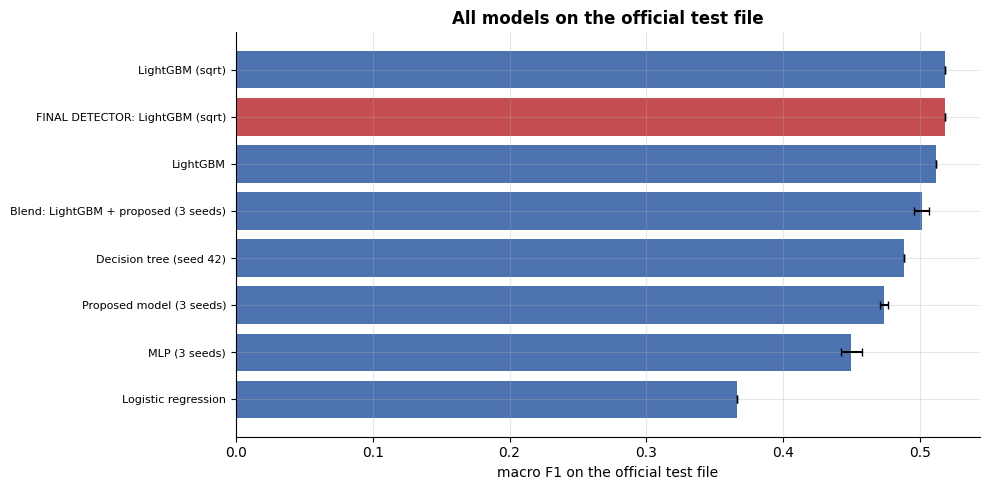

In [6]:
pre = detector.pre
rows = []


def add(name, proba_list, ms_score):
    s = pd.DataFrame([score(y_test, p) for p in proba_list])
    rows.append({'model': name, 'runs': len(proba_list), 'test macro F1': s['macro F1'].mean(),
                 'test macro F1 std': s['macro F1'].std() if len(proba_list) > 1 else np.nan,
                 'test accuracy': s['accuracy'].mean(), 'attack recall': s['attack recall'].mean(),
                 'false-positive rate': s['false-positive rate'].mean(), 'Worms (of 44)': s['Worms correct (of 13)'].mean(),
                 'model_selection macro F1': ms_score})


board = pd.concat([pd.read_csv(p, dtype={'notebook': str}) for p in sorted(TABLES.glob('leaderboard_[0-9][0-9].csv'))])
def ms(model, fs='total_and_byte44'):
    hit = board[(board.model == model) & (board['feature set'] == fs)]
    return float(hit['macro F1 mean'].iloc[0]) if len(hit) else np.nan


add('Logistic regression', [joblib.load(MODELS / '06_logistic_total_and_byte44.joblib').predict_proba(inputs['scaled'])], ms('Logistic regression'))
add('Decision tree (seed 42)', [joblib.load(MODELS / '06_decision_tree_total_and_byte44.joblib').predict_proba(inputs['tree'])], np.nan)
add('LightGBM', [joblib.load(MODELS / '10_lightgbm_none.joblib').predict_proba(inputs['tree'])], ms('LightGBM'))
treatment = detector.spec['lightgbm_treatment']
lgbm_t = joblib.load(MODELS / f'10_lightgbm_{treatment}.joblib').predict_proba(inputs['tree'])
if treatment != 'none':
    add(f'LightGBM ({treatment})', [lgbm_t], ms(f'LightGBM ({treatment})'))
add('MLP (3 seeds)', [joblib.load(MODELS / f'07_mlp_total_and_byte44_seed{s}.joblib').predict_proba(inputs['scaled']) for s in (42, 43, 44)],
    ms('MLP (128/64)'))

data = fn.FlowData('total_and_byte44')
numbers, codes = network_tensors(inputs['scaled'], pre.columns['scaled'], data.branch_a + data.branch_b)
proposed_cfg = {k: v for k, v in read_json(MODELS / '14_proposed_config.json')['config'].items() if k != 'feature_set'}
proposed = [fn.predict_proba(fn.train_network(data, proposed_cfg, s)[0], numbers, codes) for s in (42, 43, 44)]
add('Proposed model (3 seeds)', proposed, ms('Proposed model'))
add('Blend: LightGBM + proposed (3 seeds)', [(lgbm_t + p) / 2 for p in proposed], ms('Blend: LightGBM + proposed'))
add(f'FINAL DETECTOR: {detector.name}', [p_test], read_json(MODELS / 'final_detector.json')['model_selection macro F1'])

test_table = pd.DataFrame(rows).sort_values('test macro F1', ascending=False).reset_index(drop=True)
test_table['optimism (model_selection - test)'] = test_table['model_selection macro F1'] - test_table['test macro F1']
save_table(test_table, '19_test_results_all_models')
display(test_table.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
shown = test_table.iloc[::-1]
ax.barh(range(len(shown)), shown['test macro F1'], xerr=shown['test macro F1 std'].fillna(0), capsize=3,
        color=['#C44E52' if m.startswith('FINAL') else '#4C72B0' for m in shown.model])
ax.set_yticks(range(len(shown)), shown.model, fontsize=8)
ax.set(xlabel='macro F1 on the official test file', title='All models on the official test file')
plt.tight_layout(); save_figure(fig, '19_all_models_test'); plt.show()

**What we see:**

- **Every model scores much lower on the test file** than on `model_selection`: the drop ("optimism") is 0.06-0.15 macro F1. Part of it is selection
  optimism, but the size and the TTL diagnosis above point mainly to the **shift between the official training and test files**.
- **The ranking does not change:** LightGBM (sqrt) is still best (0.518), followed by plain LightGBM (0.512), the blend (0.501), the decision tree (0.488),
  the proposed network (0.474), the MLP (0.450) and logistic regression (0.366).
- The rare-class weighting still helps a little (0.518 vs 0.512) and finds more Worms (30 vs 21 of 44), but it also raises false alarms more on this
  file (32.5% vs 24.1%).
- The weighted models raise the most false alarms on this file (LightGBM sqrt 32.5%, blend 35.3%, proposed network 36.2%); the unweighted LightGBM
  (24.1%) and decision tree (22.5%) raise fewer. Up-weighting attack classes makes the shifted Normal flows even more likely to be called attacks.

## 5. Seen versus new test flows

Notebook 02 marked which test flows have an exact twin in the training file. If a model mainly recognises memorised patterns, it will do much better on
"seen" flows. (Notebook 09 predicted the opposite for this dataset, because repeated patterns carry conflicting labels.)

In [7]:
marker = pd.read_csv(DATA / '02_test_overlap_marker.csv')
assert (marker.source_id.to_numpy() == test.id.to_numpy()).all()
seen = marker.in_training_file.to_numpy()
split = pd.DataFrame([{'test flows': name, 'rows': int(mask.sum()), **score(y_test[mask], p_test[mask])}
                      for name, mask in [('seen in training file', seen), ('new', ~seen), ('all', np.ones(len(seen), bool))]]).set_index('test flows')
save_table(split, '19_seen_vs_new', index=True)
display(split[['rows', 'macro F1', 'accuracy', 'attack recall', 'false-positive rate']])

,rows,macro F1,accuracy,attack recall,false-positive rate
test flows,,,,,
seen in training file,8541,0.4077,0.5323,0.9984,0.3709
new,73791,0.5339,0.7502,0.9858,0.3230
all,82332,0.5177,0.7276,0.9878,0.3249


**What we see:**

- The 8,541 test flows that have an exact twin in the training file are predicted **worse** (macro F1 0.41, accuracy 0.53) than the 73,791 new flows
  (0.53 / 0.75). This confirms Notebook 09 on the real test file: **seen patterns are not an advantage**, because the repeated patterns are where the
  conflicting labels are, and the test file sometimes labels a twin differently from the training file.

## 6. How close is the detector to the best possible?

Inside the test file some identical flows also carry different labels. A "perfect memoriser" that always answers the most common label of each pattern
reaches the **highest overall accuracy any model could reach** on these rows (a strict limit). Its per-class recall is a **reference**, not a strict
per-class limit (as explained in Notebook 02). The memoriser cheats by knowing the test labels; it only shows how much room the labels leave.

In [8]:
predictors = [c for c in test.columns if c not in TARGETS]
pattern = test.groupby(predictors, sort=False).ngroup().to_numpy()
counts = pd.crosstab(pattern, y_test)
majority = counts.idxmax(axis=1)
ceiling_pred = majority.reindex(pattern).to_numpy()
ceiling = pd.DataFrame({'majority-vote memoriser recall': [(ceiling_pred[y_test == k] == k).mean() for k in range(10)],
                        'final detector recall': per_class.recall.to_numpy()}, index=CLASSES)
save_table(ceiling, '19_ceiling', index=True)
display(ceiling.round(3))
print(f"best possible accuracy on the test file (strict limit): {(ceiling_pred == y_test).mean():.4f} | final detector accuracy: {final_scores['accuracy']:.4f}")
print(f"macro F1 of the majority-vote memoriser (reference): {f1_score(y_test, ceiling_pred, average='macro', labels=range(10)):.4f} | "
      f"final detector macro F1: {final_scores['macro F1']:.4f}")

,majority-vote memoriser recall,final detector recall
Analysis,0.0860,0.1110
Backdoor,0.1110,0.1900
DoS,0.8380,0.4250
Exploits,0.8340,0.6840
Fuzzers,0.7950,0.6270
Generic,0.9980,0.9710
Normal,1.0000,0.6750
Reconnaissance,0.9020,0.8280
Shellcode,0.9970,0.9100
Worms,0.9770,0.6820


best possible accuracy on the test file (strict limit): 0.9360 | final detector accuracy: 0.7276
macro F1 of the majority-vote memoriser (reference): 0.7654 | final detector macro F1: 0.5177


**What we see:**

- Even a memoriser that knows the test labels could reach at most **93.6% accuracy** on this file; the detector reaches 72.8%. The memoriser's macro F1
  (0.765) shows the room the labels leave; the detector reaches 0.518.
- For **Analysis and Backdoor** the detector's recall (0.11 and 0.19) is even **above** the memoriser's (0.09 and 0.11): almost all of their test flows share
  patterns where another label is in the majority. For these two classes the labels themselves, not the detector, are the main limit.
- The largest gaps to the reference are **Normal** (0.68 vs 1.00) and **DoS** (0.43 vs 0.84): Normal because of the TTL shift above, DoS because of its
  conflict with Exploits.

## 7. Calibration and prediction sets on the test file

In [9]:
def ece(proba, y_true, bins=15):
    confidence, correct = proba.max(1), proba.argmax(1) == y_true
    edges = np.linspace(0, 1, bins + 1)
    return sum(((confidence > lo) & (confidence <= hi)).mean() * abs(confidence[(confidence > lo) & (confidence <= hi)].mean()
               - correct[(confidence > lo) & (confidence <= hi)].mean()) for lo, hi in zip(edges[:-1], edges[1:]) if ((confidence > lo) & (confidence <= hi)).any())


p_uncal = detector.raw_proba(inputs)
sets = prediction_sets(p_test, calibration['class_thresholds'])
covered = sets[np.arange(len(y_test)), y_test]
trust = pd.DataFrame({'ECE before calibration': [ece(p_uncal, y_test)], 'ECE after calibration': [ece(p_test, y_test)],
                      'set coverage (target 0.90)': [covered.mean()], 'average set size': [sets.sum(1).mean()],
                      'single-class sets': [(sets.sum(1) == 1).mean()],
                      'coverage on seen flows': [covered[seen].mean()], 'coverage on new flows': [covered[~seen].mean()]})
save_table(trust, '19_calibration_coverage')
display(trust.round(4))
display(pd.DataFrame({'coverage': [covered[y_test == k].mean() for k in range(10)], 'average set size': [sets[y_test == k].sum(1).mean() for k in range(10)]},
                     index=CLASSES).round(3))

,ECE before calibration,ECE after calibration,set coverage (target 0.90),average set size,single-class sets,coverage on seen flows,coverage on new flows
0,0.1037,0.1037,0.8025,1.3755,0.7668,0.6766,0.8171


,coverage,average set size
Analysis,0.8290,2.9990
Backdoor,0.9810,3.0690
DoS,0.6490,2.6790
Exploits,0.8480,1.8440
Fuzzers,0.7100,1.6300
Generic,0.9660,1.0240
Normal,0.7260,1.1770
Reconnaissance,0.8800,1.3370
Shellcode,0.9310,1.1720
Worms,0.9320,1.5230


**What we see:**

- **Calibration does not transfer:** the calibration error rises from 0.009 (`model_selection`) to **0.104** on the test file.
- **Conformal coverage drops to 0.80** (target 0.90). The guarantee assumes that new flows come from the same distribution as the calibration rows; the
  TTL shift breaks that assumption. Coverage stays high for Generic, Backdoor, Shellcode and Worms (0.93-0.98) and falls most for **DoS (0.65)**,
  **Fuzzers (0.71)** and **Normal (0.73)**, the classes most affected by the shift.
- Coverage is lower on seen flows (0.68) than on new flows (0.82), again because of conflicting labels between the two files.
- This is an honest, important limitation: prediction sets are only as reliable as the assumption that tomorrow's traffic looks like the calibration data.

## 8. Answers to the research questions

In [10]:
answers = pd.DataFrame([
    ('RQ1', 'Do duplicates inflate scores?', 'Notebook 09', 'Hardly (+0.004 macro F1); label conflicts dominate; deduplication biases scores downward (-0.013)'),
    ('RQ2', 'How close to the best possible?', 'Notebooks 02, 19', f"test accuracy {final_scores['accuracy']:.3f} vs strict limit "
                                                                  f"{(ceiling_pred == y_test).mean():.3f}; macro F1 {final_scores['macro F1']:.3f} vs memoriser reference "
                                                                  f"{f1_score(y_test, ceiling_pred, average='macro', labels=range(10)):.3f}"),
    ('RQ3', 'Does the proposed network beat strong baselines?', 'Notebooks 10-15, 19', 'see the test table above and the ablation in Notebook 15'),
    ('RQ4', 'Do conformal sets keep coverage and express ambiguity?', 'Notebooks 17, 19',
     f'yes on model_selection (0.928); on the shifted test file only {covered.mean():.3f} (target 0.90)'),
    ('RQ5', 'Can report claims be verified automatically?', 'Notebook 18',
     'yes: with retrieval 99% of claims and 97-100% of ATT&CK IDs pass; without sources the LLM invents IDs; unsupported items are removed automatically'),
], columns=['RQ', 'question', 'where', 'answer'])
save_table(answers, '19_research_answers')
display(answers)

,RQ,question,where,answer
0,RQ1,Do duplicates inflate scores?,Notebook 09,Hardly (+0.004 macro F1); label conflicts domi...
1,RQ2,How close to the best possible?,"Notebooks 02, 19",test accuracy 0.728 vs strict limit 0.936; mac...
2,RQ3,Does the proposed network beat strong baselines?,"Notebooks 10-15, 19",see the test table above and the ablation in N...
3,RQ4,Do conformal sets keep coverage and express am...,"Notebooks 17, 19",yes on model_selection (0.928); on the shifted...
4,RQ5,Can report claims be verified automatically?,Notebook 18,yes: with retrieval 99% of claims and 97-100% ...


## 9. Save

In [11]:
save_json({'detector': detector.name, 'test_macro_f1': final_scores['macro F1'], 'test_accuracy': final_scores['accuracy'],
           'test_attack_recall': final_scores['attack recall'], 'test_false_positive_rate': final_scores['false-positive rate'],
           'test_coverage': float(covered.mean()), 'official_test_used_once': True}, MODELS / '19_final_results.json')
print('Saved the final results. The official test file has now been used once, for evaluation only.')

Saved the final results. The official test file has now been used once, for evaluation only.


## Summary

### Final results on the official test file (used once)

| | Final detector: LightGBM with sqrt class weights |
|---|---|
| Macro F1 (10 classes) | **0.518** (0.666 on `model_selection`) |
| Accuracy | 0.728 |
| Attack recall | **98.8%** |
| False-positive rate | 32.5% |
| Worms found | 30 of 44 |
| Conformal coverage | 0.80 (target 0.90) |

### Answers to the research questions

| RQ | Answer |
|---|---|
| **RQ1** Do duplicates inflate scores? | **Hardly** (+0.004, Notebook 09); seen test flows are even predicted *worse*. Label conflicts, not leakage, are the problem; deduplication biases scores downward |
| **RQ2** How close to the best possible? | Accuracy 0.728 vs a strict limit of 0.936; Analysis and Backdoor are limited by the labels themselves |
| **RQ3** Does the proposed network beat strong baselines? | **No.** It beats the earlier networks clearly, but stays below LightGBM on `model_selection` and on the test file (0.474 vs 0.518). Its gains come mainly from class weighting, not the architecture blocks (Notebook 15) |
| **RQ4** Do conformal sets keep coverage and express ambiguity? | **Yes when the data is exchangeable** (0.928 coverage; 95% of conflicting flows get multi-class sets). **No under the train/test shift** (0.80) |
| **RQ5** Can report claims be verified automatically? | **Yes** (Notebook 18): with retrieval 99% of claims and 97-100% of ATT&CK IDs pass; without sources the LLM invents IDs; unsupported items are removed automatically |

### The main lessons for the paper

1. **Class weighting matters more than architecture** on UNSW-NB15 flows, for trees and networks alike.
2. **The official train/test files are shifted**: the test file contains many Normal flows that look like training-file attacks (marked by TTL 254),
   which causes most false alarms. Development scores on data drawn from the training file are optimistic by 0.06-0.15 macro F1 for every model.
3. **Trustworthiness tools work, but only within their assumptions:** calibration and conformal sets are excellent on matching data and degrade under shift,
   so a deployed system must monitor for drift.

### What would improve the detector next (future work)

- Adapt to the shift using the new traffic's measurements without its labels: **Notebooks 20 and 21** build and test such a detector (v2), including
  a version without the TTL columns.
- Shift-aware recalibration (Notebook 21 tests weighted conformal sets).
- Data with timestamps, endpoints and DNS queries (the full UNSW-NB15 or another dataset) for genuine temporal and DNS modelling.